In [1]:
import os
from src.utils import *
from src.models import *
from tqdm.autonotebook import tqdm
import urllib

/var/folders/wd/003_bvjd7yl44lq8ppgpklhm0000gn/T/ipykernel_64768/2982705755.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm



Loading ./data/ml-32m/raw/movies.csv...

Loaded.

Saved map_movie_to_title to .pkl file at ./data/ml-32m/preprocess
Saved movies to .pkl file at ./data/ml-32m/preprocess
Saved links to .pkl file at ./data/ml-32m/preprocess


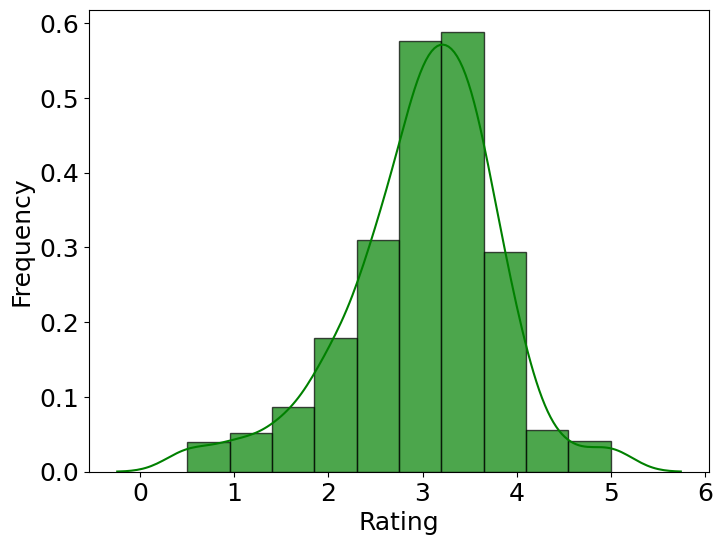

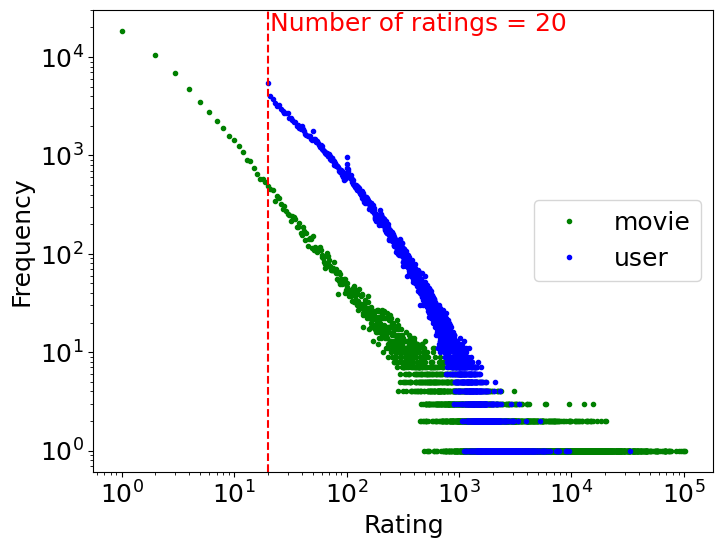

Loaded map_movie_to_id from .pkl file at ./data/ml-32m/preprocess
Loaded map_user_to_id from .pkl file at ./data/ml-32m/preprocess
Saved users_train to .npy file at experiments/ml-32m/data_split
Saved users_test to .npy file at experiments/ml-32m/data_split
Saved movies_train to .npy file at experiments/ml-32m/data_split
Saved movies_test to .npy file at experiments/ml-32m/data_split
Saved users_indices_train to .npy file at experiments/ml-32m/data_split
Saved users_indices_test to .npy file at experiments/ml-32m/data_split
Saved movies_indices_train to .npy file at experiments/ml-32m/data_split
Saved movies_indices_test to .npy file at experiments/ml-32m/data_split


In [2]:

path = './data'

folder = 'ml-32m'#'ml-latest-small'
experiment = 'experiments'

load_movie_data(path, folder)
plot_distribution(path, experiment, folder, title='', xlabel='Rating', ylabel='Frequency', color='g', kind='large')
plot_power_law_distribution(path, experiment, folder, title='', xlabel='Rating', ylabel='Frequency')
split_into_train_test(path, experiment, folder)

In [3]:
experiment_folder = os.path.join(experiment, folder)
image_folder = os.path.join(experiment_folder, "images")     # ./experiments/ml-32m/images
save_path = os.path.join(experiment_folder, 'model_files')
logs_path = os.path.join(experiment_folder, 'logs')

os.makedirs(image_folder, exist_ok=True)
os.makedirs(save_path, exist_ok=True)
os.makedirs(logs_path, exist_ok=True)

In [4]:
users_train = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'users_train')
users_test = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'users_test')
movies_train = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'movies_train')
movies_test = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'movies_test')
users_indices_train = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'users_indices_train')
users_indices_test = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'users_indices_test')
movies_indices_train = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'movies_indices_train')
movies_indices_test = load_numpy_array(os.path.join(experiment_folder, 'data_split'), 'movies_indices_test')
map_user_to_id = load_data_from_pickle(os.path.join(path, folder, 'preprocess'), 'map_user_to_id')
map_movie_to_id = load_data_from_pickle(os.path.join(path, folder, 'preprocess'),'map_movie_to_id')
map_id_to_movies = load_data_from_pickle(os.path.join(path, folder, 'preprocess'), 'map_id_to_movie')
map_id_to_movies = load_data_from_pickle(os.path.join(path, folder, 'preprocess'), 'map_id_to_movie')

Loaded users_train from .npy file at experiments/ml-32m/data_split
Loaded users_test from .npy file at experiments/ml-32m/data_split
Loaded movies_train from .npy file at experiments/ml-32m/data_split
Loaded movies_test from .npy file at experiments/ml-32m/data_split
Loaded users_indices_train from .npy file at experiments/ml-32m/data_split
Loaded users_indices_test from .npy file at experiments/ml-32m/data_split
Loaded movies_indices_train from .npy file at experiments/ml-32m/data_split
Loaded movies_indices_test from .npy file at experiments/ml-32m/data_split
Loaded map_user_to_id from .pkl file at ./data/ml-32m/preprocess
Loaded map_movie_to_id from .pkl file at ./data/ml-32m/preprocess
Loaded map_id_to_movie from .pkl file at ./data/ml-32m/preprocess
Loaded map_id_to_movie from .pkl file at ./data/ml-32m/preprocess


# Bias Only Model

In [5]:
# Hyperparameters
bias_params = load_data_from_pickle(save_path, 'params_bias').best_params
LAMBDA, GAMMA = bias_params['LAMBDA'], bias_params['GAMMA']
n_iterations = 50

# Initialize biases
n_users, n_movies = len(map_user_to_id), len(map_movie_to_id)
user_biases = np.zeros(n_users)
movie_biases = np.zeros(n_movies)

Loaded params_bias from .pkl file at experiments/ml-32m/model_files


In [6]:
bias_loss_history = []
bias_rmse_history = {'train': [], 'test': []}

with tqdm(range(n_iterations), unit='epochs') as tepochs:
    tepochs.set_description('Training')
    for _ in tepochs:
        user_biases, movie_biases = update_biases(users_train, movies_train, users_indices_train, movies_indices_train,
                    user_biases, movie_biases, LAMBDA, GAMMA)
        loss = compute_loss(users_train, users_indices_train, user_biases, movie_biases, LAMBDA, GAMMA)
        train_rmse = compute_rmse(users_indices_train, users_train, user_biases, movie_biases)
        test_rmse = compute_rmse(users_indices_test, users_test, user_biases, movie_biases)
        bias_loss_history.append(loss)
        bias_rmse_history['train'].append(train_rmse)
        bias_rmse_history['test'].append(test_rmse)
        tepochs.set_postfix(rmse_train=bias_rmse_history['train'][-1], rmse_test=bias_rmse_history['test'][-1])

os.makedirs(save_path, exist_ok=True)
save_numpy_array(save_path, user_biases, 'user_biases_b')
save_numpy_array(save_path, movie_biases, 'movie_biases_b')
save_data_to_pickle(save_path, bias_loss_history, 'bias_loss_history')
save_data_to_pickle(save_path, bias_rmse_history, 'bias_rmse_history')

Training: 100%|██████████| 50/50 [1:07:02<00:00, 80.44s/epochs, rmse_test=0.855, rmse_train=0.846]

Saved user_biases_b to .npy file at experiments/ml-32m/model_files
Saved movie_biases_b to .npy file at experiments/ml-32m/model_files
Saved bias_loss_history to .pkl file at experiments/ml-32m/model_files
Saved bias_rmse_history to .pkl file at experiments/ml-32m/model_files


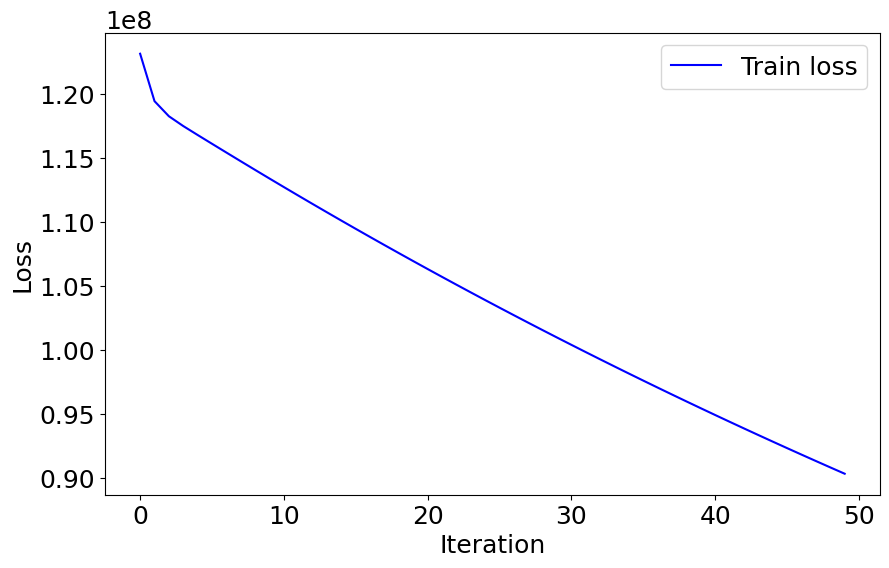

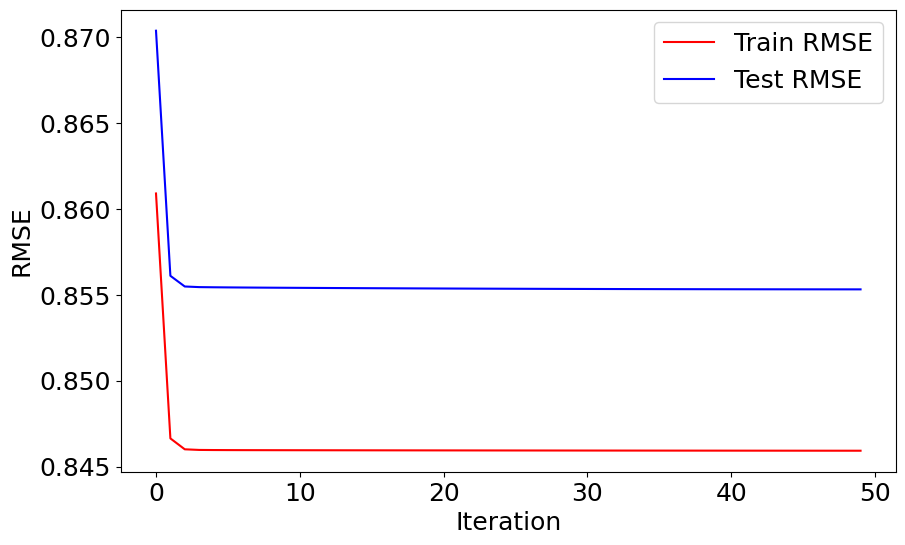

In [7]:
plot_loss_and_rmse(path, experiment, folder, bias_loss_history, bias_rmse_history, 'bias')

# Bias + Factors Method

In [8]:
# Hyperparameters
bias_factors_params = load_data_from_pickle(save_path, 'params_bias_factors').best_params
LAMBDA, GAMMA, TAU = bias_factors_params['LAMBDA'], bias_factors_params['GAMMA'], bias_factors_params['TAU']
n_iterations = 50
K = 16
SEED = 42

np.random.seed(SEED)

# Initialize biases
n_users, n_movies = len(map_user_to_id), len(map_movie_to_id)
user_biases = np.zeros(n_users)
movie_biases = np.zeros(n_movies)
user_embeddings = np.random.normal(0, 1/np.sqrt(K), size=(n_users, K))
movie_embeddings = np.random.normal(0, 1/np.sqrt(K), size=(n_movies, K))

Loaded params_bias_factors from .pkl file at experiments/ml-32m/model_files


In [9]:
bias_factors_loss_history = []
bias_factors_rmse_history = {'train': [], 'test': []}

with tqdm(range(n_iterations), unit='epochs') as tepochs:
    tepochs.set_description('Training')
    for _ in tepochs:
        user_biases, user_embeddings = update_user_biases_and_embeddings(users_train, users_indices_train, user_biases, 
                                                                        user_embeddings, movie_embeddings, movie_biases, LAMBDA, GAMMA, TAU)
        movie_biases, movie_embeddings = update_movie_biases_and_embeddings(movies_train, movies_indices_train, user_biases,
                                                                        user_embeddings, movie_embeddings, movie_biases, LAMBDA, GAMMA, TAU)
        loss = compute_loss_with_embeddings(users_train, users_indices_train, user_biases, user_embeddings, 
                                 movie_biases, movie_embeddings, LAMBDA, GAMMA, TAU)
        train_rmse = compute_rmse_with_embeddings(users_train, users_indices_train, user_biases, user_embeddings, 
                                 movie_biases, movie_embeddings)
        test_rmse = compute_rmse_with_embeddings(users_test, users_indices_test, user_biases, user_embeddings, 
                                 movie_biases, movie_embeddings)
        bias_factors_loss_history.append(loss)
        bias_factors_rmse_history['train'].append(train_rmse)
        bias_factors_rmse_history['test'].append(test_rmse)
        tepochs.set_postfix(rmse_train=bias_factors_rmse_history['train'][-1], rmse_test=bias_factors_rmse_history['test'][-1])
        
os.makedirs(save_path, exist_ok=True)
save_numpy_array(save_path, user_biases, 'user_biases')
save_numpy_array(save_path, user_embeddings, 'user_embeddings')
save_numpy_array(save_path, movie_biases, 'movie_biases')
save_numpy_array(save_path, movie_embeddings,'movie_embeddings')
save_data_to_pickle(save_path, bias_factors_loss_history, 'bias_factors_loss_history')
save_data_to_pickle(save_path, bias_factors_rmse_history, 'bias_factors_rmse_history')

Training: 100%|██████████| 50/50 [21:29<00:00, 25.78s/epochs, rmse_test=0.772, rmse_train=0.697]

Saved user_biases to .npy file at experiments/ml-32m/model_files
Saved user_embeddings to .npy file at experiments/ml-32m/model_files
Saved movie_biases to .npy file at experiments/ml-32m/model_files
Saved movie_embeddings to .npy file at experiments/ml-32m/model_files
Saved bias_factors_loss_history to .pkl file at experiments/ml-32m/model_files
Saved bias_factors_rmse_history to .pkl file at experiments/ml-32m/model_files


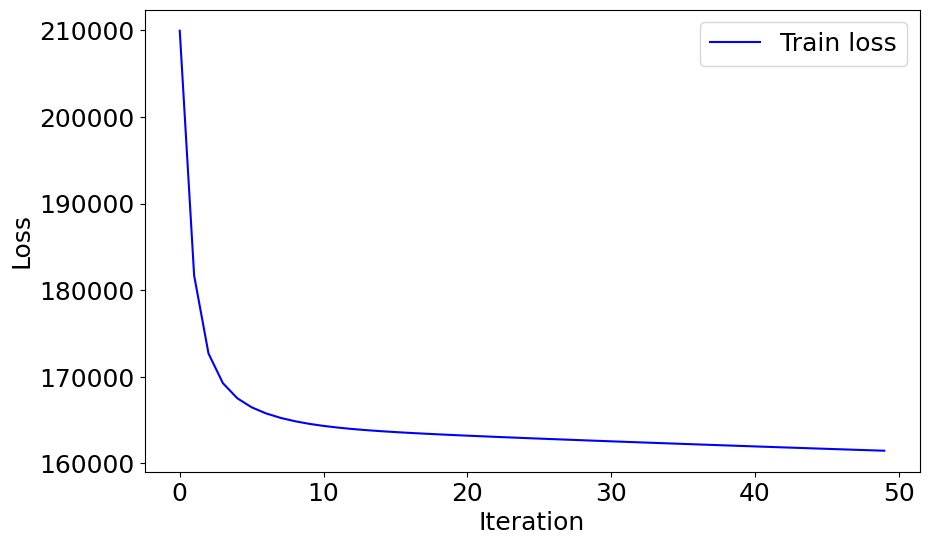

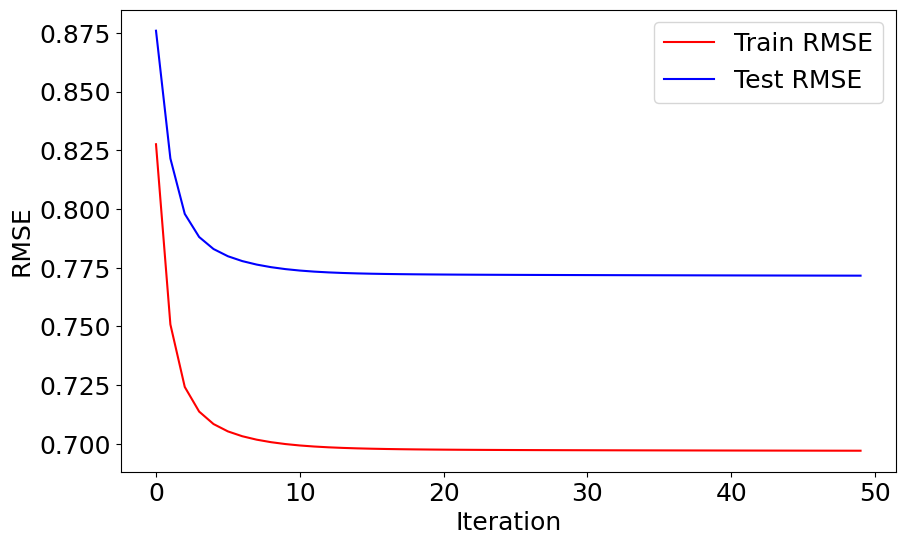

In [10]:
plot_loss_and_rmse(path, experiment, folder, bias_factors_loss_history, bias_factors_rmse_history, 'factors')

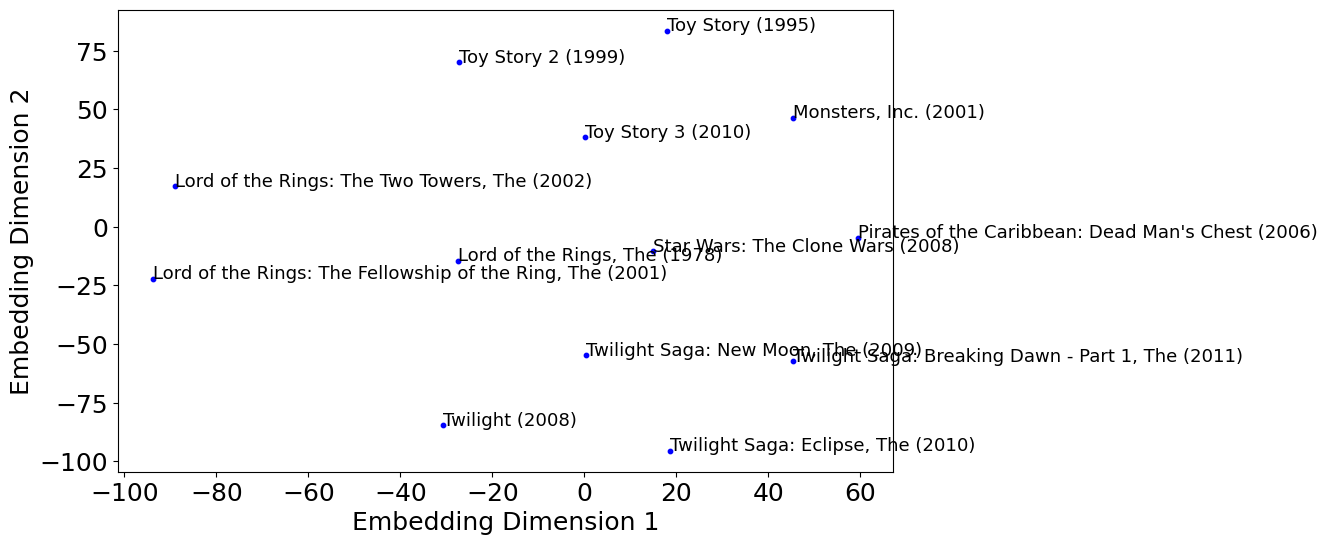

In [11]:
plot_embeddings(base_path=path, experiment_path=experiment, dataset_name=folder, use_pca=False, 
                movie_ids=[1, 2116, 3114, 4993, 5952, 45722, 63992, 72407, 78772,
                               78499, 91104, 61160, 4886])

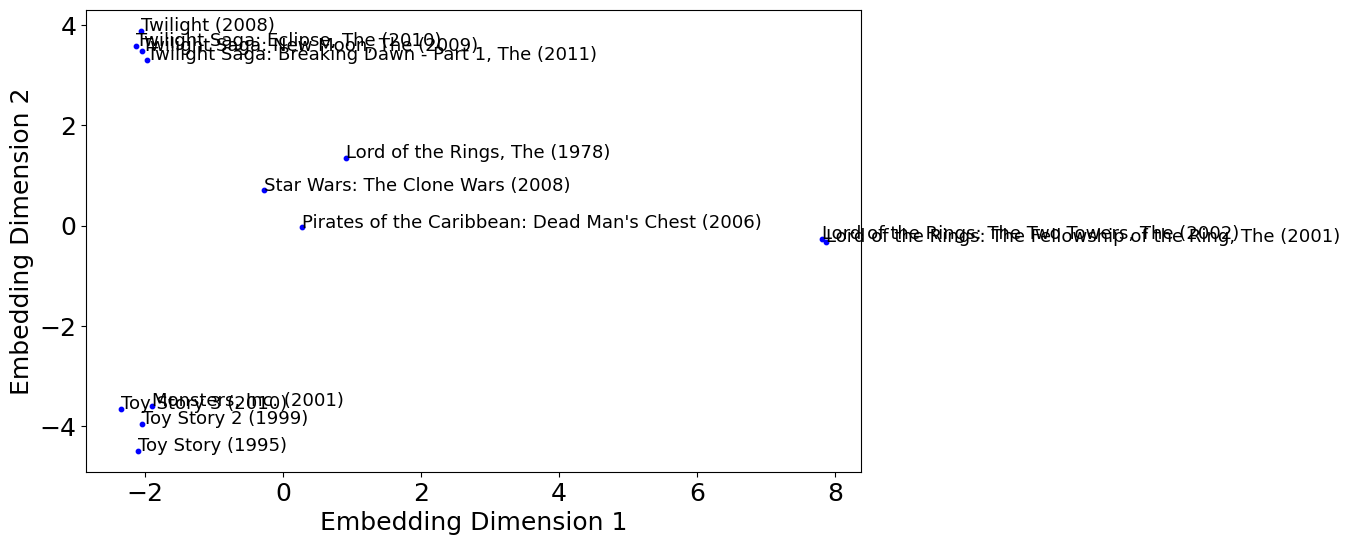

In [12]:
plot_embeddings(base_path=path, experiment_path=experiment, dataset_name=folder, use_pca=True, 
                movie_ids=[1, 2116, 3114, 4993, 5952, 45722, 63992, 72407, 78772,
                               78499, 91104, 61160, 4886])

In [13]:
recommend_movies(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[2116], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA, TAU=TAU)

Since you liked:
  - 'Lord of the Rings, The (1978)' (rating: 5)

You may also like:

1. Lord of the Rings: The Return of the King, The (2003)
2. Lord of the Rings: The Fellowship of the Ring, The (2001)
3. Lord of the Rings: The Two Towers, The (2002)
4. Star Wars: Episode I - The Phantom Menace (1999)
5. Star Wars: Episode IV - A New Hope (1977)
6. Star Wars: Episode VI - Return of the Jedi (1983)
7. Star Wars: Episode II - Attack of the Clones (2002)
8. Hobbit: An Unexpected Journey, The (2012)
9. Star Wars: Episode III - Revenge of the Sith (2005)
10. Dances with Wolves (1990)


In [ ]:
recommend_movies(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[63992], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA, TAU=TAU)

Since you liked:
  - 'Twilight (2008)' (rating: 5)

You may also like:

1. Twilight Saga: Eclipse, The (2010)
2. Twilight Saga: New Moon, The (2009)
3. Titanic (1997)
4. Twilight Saga: Breaking Dawn - Part 1, The (2011)
5. Twilight Saga: Breaking Dawn - Part 2, The (2012)
6. Grease (1978)
7. Notebook, The (2004)
8. Avatar (2009)
9. Bridget Jones's Diary (2001)
10. Pretty Woman (1990)


In [16]:
recommend_movies(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[4993], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA, TAU=TAU)

Since you liked:
  - 'Lord of the Rings: The Fellowship of the Ring, The (2001)' (rating: 5)

You may also like:

1. Lord of the Rings: The Return of the King, The (2003)
2. Lord of the Rings: The Two Towers, The (2002)
3. Star Wars: Episode IV - A New Hope (1977)
4. Braveheart (1995)
5. Star Wars: Episode V - The Empire Strikes Back (1980)
6. Star Wars: Episode VI - Return of the Jedi (1983)
7. Hobbit: An Unexpected Journey, The (2012)
8. Star Wars: Episode I - The Phantom Menace (1999)
9. Blair Witch Project, The (1999)
10. Hobbit: The Desolation of Smaug, The (2013)


In [15]:
recommend_movies(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[4896], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA, TAU=TAU)

Since you liked:
  - 'Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)' (rating: 5)

You may also like:

1. Harry Potter and the Prisoner of Azkaban (2004)
2. Harry Potter and the Chamber of Secrets (2002)
3. Harry Potter and the Goblet of Fire (2005)
4. Harry Potter and the Half-Blood Prince (2009)
5. Harry Potter and the Order of the Phoenix (2007)
6. Harry Potter and the Deathly Hallows: Part 1 (2010)
7. Harry Potter and the Deathly Hallows: Part 2 (2011)
8. Independence Day (a.k.a. ID4) (1996)
9. Batman Forever (1995)
10. Pirates of the Caribbean: The Curse of the Black Pearl (2003)


In [30]:
recommend_movies(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[1], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA, TAU=TAU)

Since you liked:
  - 'Toy Story (1995)' (rating: 5)

You may also like:

1. Toy Story 2 (1999)
2. Toy Story 3 (2010)
3. Finding Nemo (2003)
4. Monsters, Inc. (2001)
5. Beauty and the Beast (1991)
6. Aladdin (1992)
7. Incredibles, The (2004)
8. WALL·E (2008)
9. Up (2009)
10. Lion King, The (1994)


In [33]:
recommend_movies_bias_only_streamlit(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[1], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA)

['Black Harvest (1992)',
 'Wesley (2009)',
 'SpongeBob SquarePants: Tide and Seek',
 'WWE: The Triumph and Tragedy of World Class Championship Wrestling (2007)',
 'The Viking (1931)',
 'Visions of Frank (2007)',
 "Anybody's Son Will Do",
 "Evening's Civil Twilight in Empires of Tin (2008)",
 'The Revolutionary (2011)',
 'Jeff Ross Roasts the Border (2017)']

In [36]:
recommend_movies_bias_only(base_path=path, experiment_path=experiment, dataset_name=folder, 
                 movie_ids=[1], movie_ratings=[5], top_n = 10, LAMBDA=LAMBDA, GAMMA=GAMMA)

Since you liked:
  - 'Toy Story (1995)' (rating: 5)

You may also like:

1. Black Harvest (1992)
2. Wesley (2009)
3. SpongeBob SquarePants: Tide and Seek
4. WWE: The Triumph and Tragedy of World Class Championship Wrestling (2007)
5. The Viking (1931)
6. Visions of Frank (2007)
7. Anybody's Son Will Do
8. Evening's Civil Twilight in Empires of Tin (2008)
9. The Revolutionary (2011)
10. Jeff Ross Roasts the Border (2017)
